# Augmented Synthetic Control for staggered rent control adoption

This notebook implements a **cohort-pooled ASCM robustness check** for the Catalonia rent-control setting.

Because the available Python tooling implements **single treated-unit ASCM** directly, this notebook proceeds in three steps:

1. Build a **pooled treated unit** for each treatment cohort (`2024Q2`, `2025Q1`) by averaging the outcome across municipalities in that cohort.
2. Fit **Augmented Synthetic Control** separately for each cohort against the **never-treated donor pool**.
3. Aggregate the cohort-specific post-treatment effects using **treated-municipality weights**.

This is a pragmatic Python implementation of a staggered-adoption ASCM workflow. It is not literally the same object as the `multisynth()` routine in the R `augsynth` package, but it is aligned with the same BMFR augmented-synthetic-control logic and is well suited as the next robustness step after the TWFE, C&S-style staggered DiD, and PSM-based analyses.

In [1]:

from pathlib import Path
import importlib
import subprocess
import sys
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
from pysyncon import Dataprep, AugSynth

In [2]:

def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").exists() and (candidate / "src").exists():
            return candidate
    return start

ROOT = find_project_root()
OUT_DIR = ROOT / "out"
OUT_DIR.mkdir(parents=True, exist_ok=True)

candidate_paths = [
    OUT_DIR / "analysis_ready_panel_fixed.pkl",
    OUT_DIR / "analysis_ready_panel_fixed.jsonl",
    OUT_DIR / "analysis_ready_panel.pkl",
    OUT_DIR / "analysis_ready_panel.jsonl",
]

panel_path = next((p for p in candidate_paths if p.exists()), None)
if panel_path is None:
    raise FileNotFoundError(
        "Could not find analysis_ready_panel[_fixed].pkl/jsonl in ROOT/out"
    )

if panel_path.suffix == ".pkl":
    panel = pd.read_pickle(panel_path)
else:
    panel = pd.read_json(panel_path, lines=True)

print("ROOT:", ROOT)
print("Loaded:", panel_path)
print("Shape:", panel.shape)
display(panel.head())

ROOT: /home/venatio/documents/university/public-sector-2026
Loaded: /home/venatio/documents/university/public-sector-2026/out/analysis_ready_panel.pkl
Shape: (56908, 61)


,Code,Municipality,municipality_norm,Year,Quarter,quarter_num,time_index,Prices,Contracts,price_observed_raw,contracts_observed_raw,price_imputed,contracts_imputed,has_any_observed_price,has_any_observed_contracts,exclude_from_price_analysis,exclude_from_contract_analysis,has_valid_price_for_analysis,has_valid_contracts_for_analysis,Treated 1,Treated 2,Control,ever_treated,cohort,first_treat_period,first_treat_index,treated,event_time,pop_total,pop_males,pop_females,pop_native_total,pop_native_males,pop_native_females,pop_foreign_total,pop_foreign_males,pop_foreign_females,mig_total,mig_total_males,mig_total_females,mig_inflows,mig_inflows_males,mig_inflows_females,mig_outflows,mig_outflows_males,mig_outflows_females,income_tax_base,income_tax_liability,log_prices,price_growth_qoq_pct,price_growth_yoy_pct,log_price_growth_qoq,log_price_growth_yoy,contracts_per_10k,contracts_per_10k_qoq_pct,contracts_per_10k_yoy_pct,rent_to_income_proxy,annualized_rent_to_income_proxy,rent_to_tax_liability_proxy,outcome_price_growth,outcome_market_activity
0,00005,NaN,,2015,Q1,1,8061,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,00005,NaN,,2015,Q2,2,8062,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,00005,NaN,,2015,Q3,3,8063,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,00005,NaN,,2015,Q4,4,8064,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,02050,NaN,,2011,Q1,1,8045,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Study design choices

These are the design choices hard-coded below:

- **Window:** `2022Q1` to `2025Q4`
- **Treatment cohorts:** `2024Q2`, `2025Q1`
- **Control pool:** `Never` treated municipalities only
- **Outcomes:**
  - rent growth: `outcome_price_growth`
  - market activity: `outcome_market_activity`
- **Validity flags:**
  - rent: `has_valid_price_for_analysis == 1`
  - contracts: `has_valid_contracts_for_analysis == 1`

The window matches the cleaner design logic discussed in the proposal: a recent pre-period and the short post-period after the 2024 activation waves.

In [3]:

WINDOW_START = 2022 * 4 + 1   # 2022Q1
WINDOW_END   = 2025 * 4 + 4   # 2025Q4

COHORT_STARTS = {
    "2024Q2": 2024 * 4 + 2,
    "2025Q1": 2025 * 4 + 1,
}

RENT_OUTCOME = "outcome_price_growth"
CONTRACTS_OUTCOME = "outcome_market_activity"

RENT_VALID_FLAG = "has_valid_price_for_analysis"
CONTRACTS_VALID_FLAG = "has_valid_contracts_for_analysis"

# Conservative predictor set with high coverage.
COMMON_PREDICTORS = ["pop_total", "income_tax_base"]

quarter_to_num = {"Q1": 1, "Q2": 2, "Q3": 3, "Q4": 4}
if "quarter_num" not in panel.columns:
    panel["quarter_num"] = panel["Quarter"].map(quarter_to_num)

if "time_index" not in panel.columns:
    panel["time_index"] = panel["Year"].astype(int) * 4 + panel["quarter_num"].astype(int)

panel = panel.copy()
panel["Code"] = panel["Code"].astype(str).str.zfill(5)
panel["Municipality"] = panel["Municipality"].astype(str)

panel = panel[panel["Municipality"].notna() & (panel["Municipality"].str.strip() != "")].copy()
panel = panel.loc[panel["time_index"].between(WINDOW_START, WINDOW_END)].copy()
panel = panel.sort_values(["Code", "time_index"]).reset_index(drop=True)

print("Panel shape in ASCM window:", panel.shape)
print("Municipalities in window:", panel["Code"].nunique())
display(panel[["Code", "Municipality", "Year", "Quarter", "cohort", "treated"]].head())

Panel shape in ASCM window: (15152, 61)
Municipalities in window: 947


,Code,Municipality,Year,Quarter,cohort,treated
0,08001,Abrera,2022,Q1,2024Q2,0
1,08001,Abrera,2022,Q2,2024Q2,0
2,08001,Abrera,2022,Q3,2024Q2,0
3,08001,Abrera,2022,Q4,2024Q2,0
4,08001,Abrera,2023,Q1,2024Q2,0


In [4]:

def time_index_to_period_label(t: int) -> str:
    year = int((t - 1) // 4)
    quarter_num = int(t - year * 4)
    quarter = {1: "Q1", 2: "Q2", 3: "Q3", 4: "Q4"}[quarter_num]
    return f"{year}-{quarter}"

def stars(p):
    if pd.isna(p):
        return ""
    if p < 0.01:
        return "***"
    if p < 0.05:
        return "**"
    if p < 0.10:
        return "*"
    return ""

def normal_two_sided_p(z):
    if pd.isna(z):
        return np.nan
    Phi = 0.5 * (1 + math.erf(abs(float(z)) / math.sqrt(2)))
    return 2 * (1 - Phi)

def as_numeric(df, cols):
    out = df.copy()
    for c in cols:
        if c in out.columns:
            out[c] = pd.to_numeric(out[c], errors="coerce")
    return out

panel = as_numeric(panel, [
    RENT_OUTCOME, CONTRACTS_OUTCOME,
    RENT_VALID_FLAG, CONTRACTS_VALID_FLAG,
    "pop_total", "income_tax_base",
])

## Helper functions

The key functions below do the following:

- build a **balanced cohort-specific synthetic-control study dataset**
- construct a **pooled treated unit**
- fit `AugSynth`
- extract post-treatment ATT by period
- aggregate cohort-specific results using treated-municipality weights

In [5]:

def build_study_frame(
    panel_df: pd.DataFrame,
    outcome_col: str,
    valid_flag_col: str,
    cohort_label: str,
    predictors: list[str],
) -> tuple[pd.DataFrame, dict]:
    treat_start = COHORT_STARTS[cohort_label]
    periods = list(range(WINDOW_START, WINDOW_END + 1))
    pre_periods = [t for t in periods if t < treat_start]
    post_periods = [t for t in periods if t >= treat_start]

    treated_units = panel_df.loc[
        (panel_df["cohort"] == cohort_label),
        ["Code", "Municipality"]
    ].drop_duplicates()

    donor_units = panel_df.loc[
        (panel_df["cohort"] == "Never"),
        ["Code", "Municipality"]
    ].drop_duplicates()

    needed_cols = ["Code", "Municipality", "time_index", outcome_col, valid_flag_col] + predictors
    work = panel_df.loc[:, [c for c in needed_cols if c in panel_df.columns]].copy()

    def unit_is_complete(g):
        cond_outcome = g[outcome_col].notna().all()
        cond_valid = (g[valid_flag_col].fillna(0) == 1).all()
        cond_time = set(g["time_index"]) == set(periods)
        cond_predictors = g[predictors].notna().all().all()
        return bool(cond_outcome and cond_valid and cond_time and cond_predictors)

    complete_mask = (
        work.groupby("Code")
            .apply(unit_is_complete)
            .rename("is_complete")
            .reset_index()
    )

    work = work.merge(complete_mask, on="Code", how="left")
    work = work.loc[work["is_complete"] == True].copy()

    treated_codes = set(treated_units["Code"]) & set(work["Code"].unique())
    donor_codes = set(donor_units["Code"]) & set(work["Code"].unique())

    if len(treated_codes) == 0:
        raise ValueError(f"No complete treated municipalities left for cohort {cohort_label} and outcome {outcome_col}.")
    if len(donor_codes) < 5:
        raise ValueError(f"Too few complete never-treated donors left for cohort {cohort_label} and outcome {outcome_col}.")

    treated_frame = work.loc[work["Code"].isin(treated_codes)].copy()
    donor_frame = work.loc[work["Code"].isin(donor_codes)].copy()

    treated_pooled = (
        treated_frame.groupby("time_index", as_index=False)[[outcome_col] + predictors]
        .mean()
        .assign(
            unit_id=f"TREATED_{cohort_label}",
            unit_name=f"Pooled treated {cohort_label}"
        )
    )

    donor_long = donor_frame.rename(columns={"Code": "unit_id", "Municipality": "unit_name"}).copy()

    study = pd.concat(
        [
            donor_long[["unit_id", "unit_name", "time_index", outcome_col] + predictors],
            treated_pooled[["unit_id", "unit_name", "time_index", outcome_col] + predictors],
        ],
        ignore_index=True,
    )

    meta = {
        "cohort": cohort_label,
        "treated_unit_id": f"TREATED_{cohort_label}",
        "treated_n_municipalities": len(treated_codes),
        "donor_n_municipalities": len(donor_codes),
        "pre_periods": pre_periods,
        "post_periods": post_periods,
        "treatment_time": treat_start,
        "periods": periods,
        "treated_codes": sorted(treated_codes),
        "donor_codes": sorted(donor_codes),
    }
    return study, meta

In [6]:

def fit_augsynth_study(
    study_df: pd.DataFrame,
    outcome_col: str,
    predictors: list[str],
    meta: dict,
):
    special_predictors = [(outcome_col, [t], "mean") for t in meta["pre_periods"]]

    dataprep = Dataprep(
        foo=study_df,
        predictors=predictors,
        predictors_op="mean",
        time_predictors_prior=meta["pre_periods"],
        special_predictors=special_predictors,
        dependent=outcome_col,
        unit_variable="unit_id",
        time_variable="time_index",
        treatment_identifier=meta["treated_unit_id"],
        controls_identifier=[u for u in study_df["unit_id"].unique() if u != meta["treated_unit_id"]],
        time_optimize_ssr=meta["pre_periods"],
    )

    model = AugSynth()
    model.fit(dataprep)

    overall = model.att(meta["post_periods"])
    overall_att = float(overall.get("att", np.nan))
    overall_se = float(overall.get("se", np.nan))

    dynamic_rows = []
    for t in meta["post_periods"]:
        res = model.att([t])
        dynamic_rows.append({
            "cohort": meta["cohort"],
            "time_index": t,
            "period": time_index_to_period_label(t),
            "event_time": t - meta["treatment_time"],
            "att": float(res.get("att", np.nan)),
            "se": float(res.get("se", np.nan)),
            "treated_n_municipalities": meta["treated_n_municipalities"],
        })

    dynamic = pd.DataFrame(dynamic_rows)
    dynamic["ci_low"] = dynamic["att"] - 1.96 * dynamic["se"]
    dynamic["ci_high"] = dynamic["att"] + 1.96 * dynamic["se"]

    fit_stats = {
        "pre_mae": float(model.mae()),
        "pre_mspe": float(model.mspe()),
    }

    summary = pd.DataFrame([{
        "cohort": meta["cohort"],
        "att": overall_att,
        "se": overall_se,
        "z": overall_att / overall_se if pd.notna(overall_se) and overall_se > 0 else np.nan,
        "p_value": normal_two_sided_p(overall_att / overall_se) if pd.notna(overall_se) and overall_se > 0 else np.nan,
        "ci_low": overall_att - 1.96 * overall_se if pd.notna(overall_se) else np.nan,
        "ci_high": overall_att + 1.96 * overall_se if pd.notna(overall_se) else np.nan,
        "att_stars": f"{overall_att:.4f}{stars(normal_two_sided_p(overall_att / overall_se) if pd.notna(overall_se) and overall_se > 0 else np.nan)}" if pd.notna(overall_att) else np.nan,
        "n_treated_municipalities": meta["treated_n_municipalities"],
        "n_donor_municipalities": meta["donor_n_municipalities"],
        "n_pre_periods": len(meta["pre_periods"]),
        "n_post_periods": len(meta["post_periods"]),
        "pre_mae": fit_stats["pre_mae"],
        "pre_mspe": fit_stats["pre_mspe"],
    }])

    return {
        "model": model,
        "dataprep": dataprep,
        "meta": meta,
        "summary": summary,
        "dynamic": dynamic,
        "study_df": study_df.copy(),
    }

In [7]:

def aggregate_cohort_summaries(cohort_results: list[dict], outcome_label: str):
    cohort_table = pd.concat(
        [r["summary"].assign(outcome=outcome_label) for r in cohort_results],
        ignore_index=True,
    )

    weights = cohort_table["n_treated_municipalities"].to_numpy(dtype=float)
    atts = cohort_table["att"].to_numpy(dtype=float)
    ses = cohort_table["se"].to_numpy(dtype=float)

    w_sum = weights.sum()
    att = np.sum(weights * atts) / w_sum
    se = np.sqrt(np.sum((weights ** 2) * (ses ** 2))) / w_sum
    z = att / se if pd.notna(se) and se > 0 else np.nan
    p = normal_two_sided_p(z) if pd.notna(z) else np.nan

    agg = pd.DataFrame([{
        "Outcome": outcome_label,
        "att": att,
        "se": se,
        "z": z,
        "p_value": p,
        "ci_low": att - 1.96 * se if pd.notna(se) else np.nan,
        "ci_high": att + 1.96 * se if pd.notna(se) else np.nan,
        "att_stars": f"{att:.4f}{stars(p)}" if pd.notna(att) else np.nan,
        "N cohorts": len(cohort_results),
        "Treated municipalities (weighted sum)": int(w_sum),
        "Cohorts": ", ".join(cohort_table["cohort"].tolist()),
        "Control group": "Never treated only",
        "Estimation window": f"{time_index_to_period_label(WINDOW_START)} to {time_index_to_period_label(WINDOW_END)}",
        "Method": "Cohort-pooled ASCM with treated-municipality weighting",
    }])

    return cohort_table, agg

def aggregate_dynamic_paths(cohort_results: list[dict], outcome_label: str):
    dyn = pd.concat([r["dynamic"] for r in cohort_results], ignore_index=True).copy()

    grouped = []
    for e, g in dyn.groupby("event_time"):
        w = g["treated_n_municipalities"].to_numpy(dtype=float)
        a = g["att"].to_numpy(dtype=float)
        s = g["se"].to_numpy(dtype=float)
        w_sum = w.sum()
        att = np.sum(w * a) / w_sum
        se = np.sqrt(np.sum((w ** 2) * (s ** 2))) / w_sum
        grouped.append({
            "Outcome": outcome_label,
            "event_time": e,
            "att": att,
            "se": se,
            "ci_low": att - 1.96 * se if pd.notna(se) else np.nan,
            "ci_high": att + 1.96 * se if pd.notna(se) else np.nan,
            "n_cohorts": g["cohort"].nunique(),
            "treated_weight": int(w_sum),
        })

    return pd.DataFrame(grouped).sort_values("event_time").reset_index(drop=True)

## Run ASCM by outcome

In [8]:

RENT_PREDICTORS = COMMON_PREDICTORS.copy()
CONTRACTS_PREDICTORS = COMMON_PREDICTORS.copy()

def run_staggered_ascm(panel_df, outcome_col, valid_flag_col, outcome_label, predictors):
    cohort_results = []
    for cohort_label in ["2024Q2", "2025Q1"]:
        study, meta = build_study_frame(
            panel_df=panel_df,
            outcome_col=outcome_col,
            valid_flag_col=valid_flag_col,
            cohort_label=cohort_label,
            predictors=predictors,
        )
        res = fit_augsynth_study(
            study_df=study,
            outcome_col=outcome_col,
            predictors=predictors,
            meta=meta,
        )
        cohort_results.append(res)

    cohort_summary, agg_summary = aggregate_cohort_summaries(cohort_results, outcome_label)
    dynamic_agg = aggregate_dynamic_paths(cohort_results, outcome_label)

    return {
        "cohort_results": cohort_results,
        "cohort_summary": cohort_summary,
        "agg_summary": agg_summary,
        "dynamic_agg": dynamic_agg,
    }

warnings.filterwarnings("ignore", category=RuntimeWarning)

In [9]:
rent_results = run_staggered_ascm(
    panel_df=panel,
    outcome_col=RENT_OUTCOME,
    valid_flag_col=RENT_VALID_FLAG,
    outcome_label="Rent growth (YoY, pp)",
    predictors=RENT_PREDICTORS,
)

display(rent_results["cohort_summary"])
display(rent_results["agg_summary"])

,cohort,att,se,z,p_value,ci_low,ci_high,att_stars,n_treated_municipalities,n_donor_municipalities,n_pre_periods,n_post_periods,pre_mae,pre_mspe,outcome
0,2024Q2,-5.4569,1.3948,-3.9122,0.0001,-8.1907,-2.7230,-5.4569***,140,257,9,7,1.5761,3.0807,"Rent growth (YoY, pp)"
1,2025Q1,-5.3838,0.7904,-6.8118,0.0000,-6.9329,-3.8347,-5.3838***,131,257,12,4,0.1268,0.0217,"Rent growth (YoY, pp)"


,Outcome,att,se,z,p_value,ci_low,ci_high,att_stars,N cohorts,Treated municipalities (weighted sum),Cohorts,Control group,Estimation window,Method
0,"Rent growth (YoY, pp)",-5.4215,0.8156,-6.6473,0.0000,-7.0201,-3.8230,-5.4215***,2,271,"2024Q2, 2025Q1",Never treated only,2022-Q1 to 2025-Q4,Cohort-pooled ASCM with treated-municipality w...


In [10]:

contracts_results = run_staggered_ascm(
    panel_df=panel,
    outcome_col=CONTRACTS_OUTCOME,
    valid_flag_col=CONTRACTS_VALID_FLAG,
    outcome_label="Tenancy agreements per 10k",
    predictors=CONTRACTS_PREDICTORS,
)

display(contracts_results["cohort_summary"])
display(contracts_results["agg_summary"])

,cohort,att,se,z,p_value,ci_low,ci_high,att_stars,n_treated_municipalities,n_donor_municipalities,n_pre_periods,n_post_periods,pre_mae,pre_mspe,outcome
0,2024Q2,-4.0596,2.2589,-1.7972,0.0723,-8.4870,0.3678,-4.0596*,140,676,9,7,2.9724,10.2125,Tenancy agreements per 10k
1,2025Q1,0.2998,3.6444,0.0823,0.9344,-6.8433,7.4429,0.2998,131,676,12,4,0.3189,0.1164,Tenancy agreements per 10k


,Outcome,att,se,z,p_value,ci_low,ci_high,att_stars,N cohorts,Treated municipalities (weighted sum),Cohorts,Control group,Estimation window,Method
0,Tenancy agreements per 10k,-1.9523,2.1131,-0.9239,0.3555,-6.0941,2.1894,-1.9523,2,271,"2024Q2, 2025Q1",Never treated only,2022-Q1 to 2025-Q4,Cohort-pooled ASCM with treated-municipality w...


## Cohort-specific fit diagnostics

These tables help answer two practical questions:

- How good is pre-treatment fit (`pre_mae`, `pre_mspe`)?
- Are both cohorts contributing meaningfully to the pooled result?

In [11]:

cohort_fit = pd.concat(
    [
        rent_results["cohort_summary"].assign(Outcome="Rent growth (YoY, pp)"),
        contracts_results["cohort_summary"].assign(Outcome="Tenancy agreements per 10k"),
    ],
    ignore_index=True,
)

cohort_fit = cohort_fit[[
    "Outcome", "cohort", "att", "se", "p_value", "att_stars",
    "n_treated_municipalities", "n_donor_municipalities",
    "n_pre_periods", "n_post_periods", "pre_mae", "pre_mspe"
]]

display(cohort_fit)

,Outcome,cohort,att,se,p_value,att_stars,n_treated_municipalities,n_donor_municipalities,n_pre_periods,n_post_periods,pre_mae,pre_mspe
0,"Rent growth (YoY, pp)",2024Q2,-5.4569,1.3948,0.0001,-5.4569***,140,257,9,7,1.5761,3.0807
1,"Rent growth (YoY, pp)",2025Q1,-5.3838,0.7904,0.0000,-5.3838***,131,257,12,4,0.1268,0.0217
2,Tenancy agreements per 10k,2024Q2,-4.0596,2.2589,0.0723,-4.0596*,140,676,9,7,2.9724,10.2125
3,Tenancy agreements per 10k,2025Q1,0.2998,3.6444,0.9344,0.2998,131,676,12,4,0.3189,0.1164


## Dynamic ASCM paths

These are post-treatment dynamic ATT profiles. They are the ASCM counterpart to the dynamic ATT plots used in the staggered DiD stage, but now the counterfactual path for each cohort is synthetic rather than donor-average.

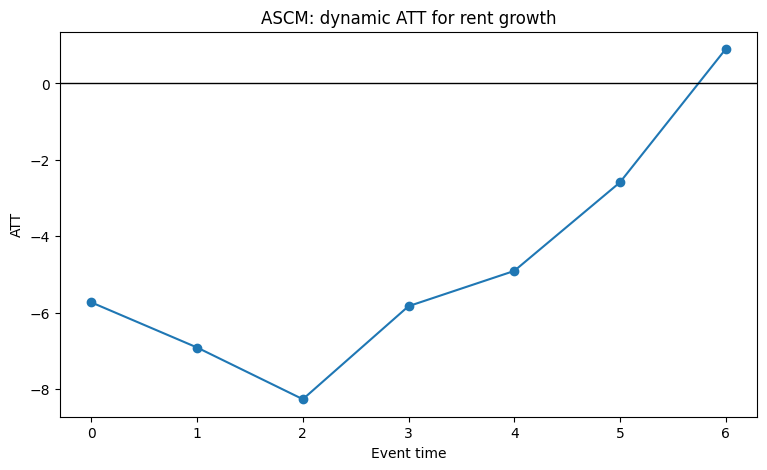

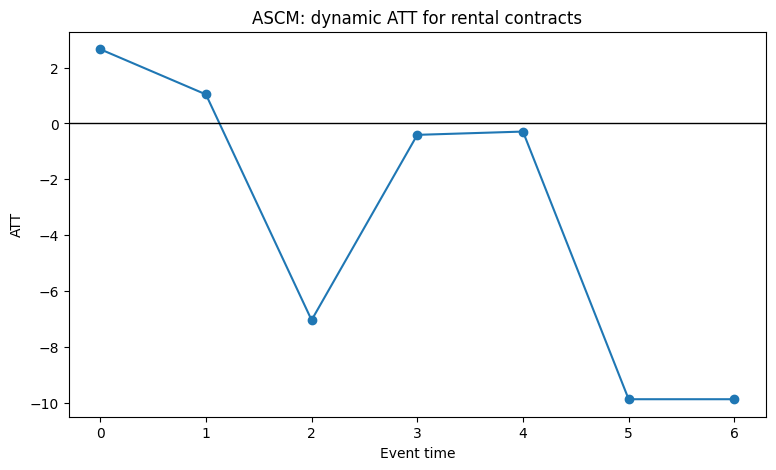

In [12]:

def plot_dynamic(result_dict, title):
    dyn = result_dict["dynamic_agg"].copy()
    plt.figure(figsize=(9, 5))
    plt.plot(dyn["event_time"], dyn["att"], marker="o")
    plt.fill_between(dyn["event_time"], dyn["ci_low"], dyn["ci_high"], alpha=0.2)
    plt.axhline(0, color="black", linewidth=1)
    plt.xlabel("Event time")
    plt.ylabel("ATT")
    plt.title(title)
    plt.show()

plot_dynamic(rent_results, "ASCM: dynamic ATT for rent growth")
plot_dynamic(contracts_results, "ASCM: dynamic ATT for rental contracts")

## Optional gap plots by cohort

`pysyncon` can draw a treated-minus-synthetic gap plot for each cohort-specific ASCM study. These are often useful for visual inspection of fit and post-treatment divergence.

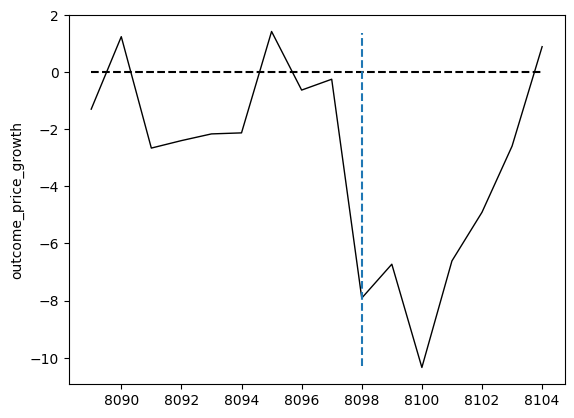

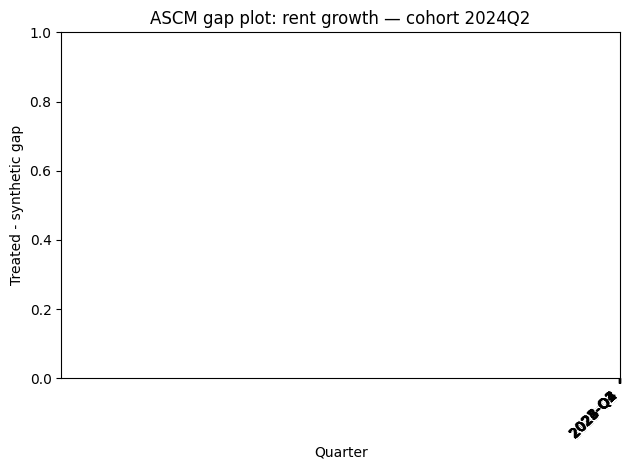

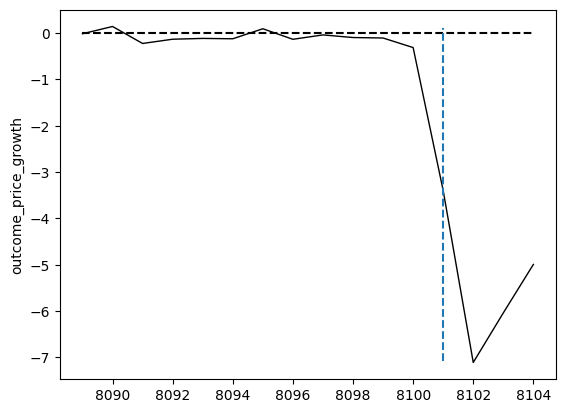

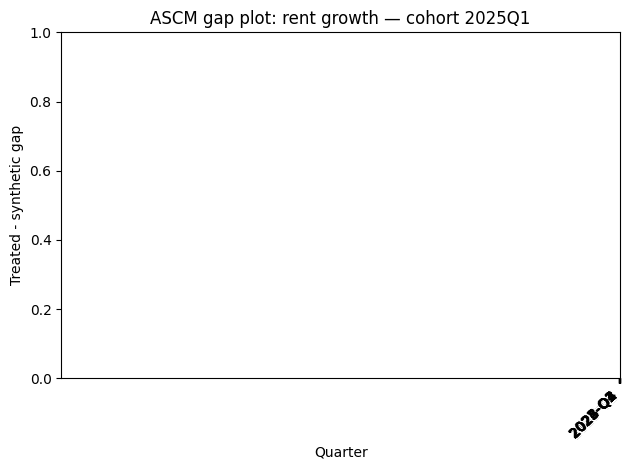

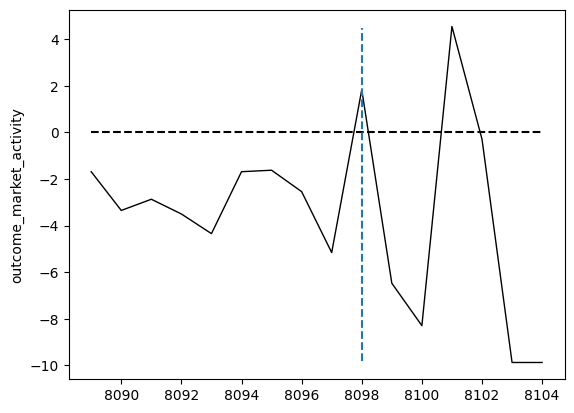

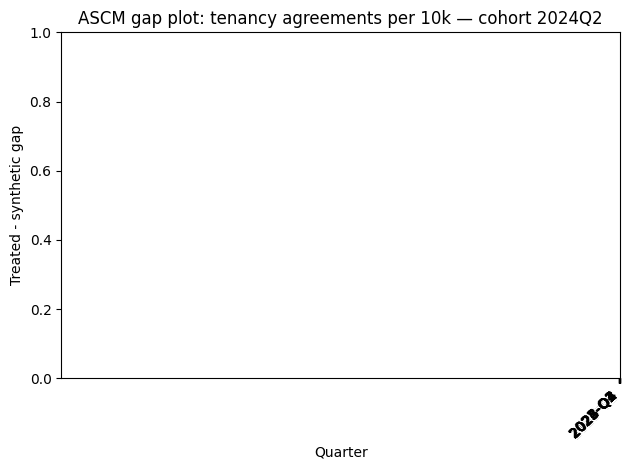

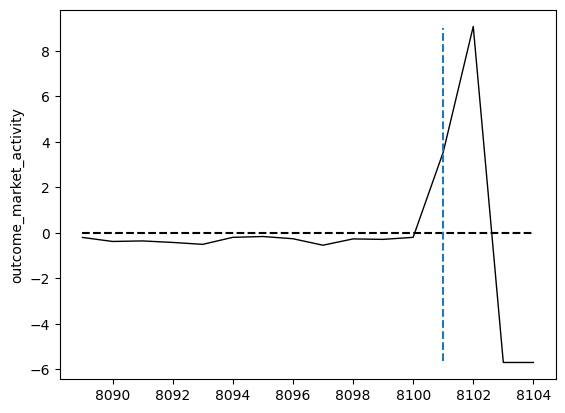

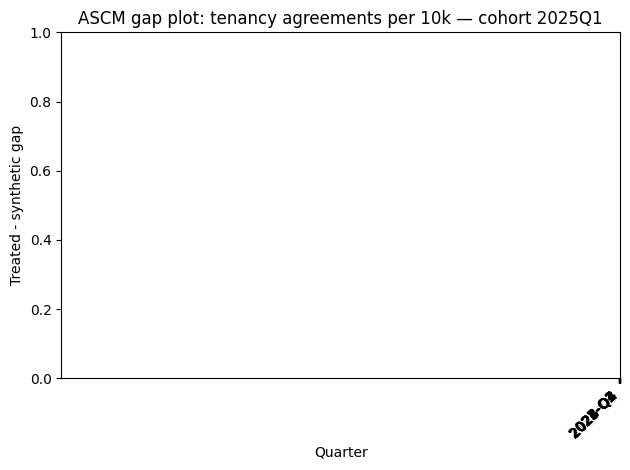

In [13]:
## Optional gap plots by cohort

def plot_gap_with_calendar_labels(res, title, y_label):
    periods = res["meta"]["periods"]
    treatment_time = res["meta"]["treatment_time"]
    labels = [time_index_to_period_label(t) for t in periods]

    # Let pysyncon draw the gap plot
    res["model"].gaps_plot(
        time_period=periods,
        treatment_time=treatment_time,
        grid=False,
    )

    ax = plt.gca()

    # Force grid off in case the package still draws it
    ax.grid(False)

    # Replace weird numeric codes with readable quarter labels
    ax.set_xticks(periods)
    ax.set_xticklabels(labels, rotation=45, ha="right")

    ax.set_xlabel("Quarter")
    ax.set_ylabel(y_label)
    ax.set_title(title)

    plt.tight_layout()
    plt.show()


for res in rent_results["cohort_results"]:
    plot_gap_with_calendar_labels(
        res,
        title=f"ASCM gap plot: rent growth — cohort {res['meta']['cohort']}",
        y_label="Treated - synthetic gap",
    )

for res in contracts_results["cohort_results"]:
    plot_gap_with_calendar_labels(
        res,
        title=f"ASCM gap plot: tenancy agreements per 10k — cohort {res['meta']['cohort']}",
        y_label="Treated - synthetic gap",
    )

## Assemble final summary tables

In [14]:

ascm_summary = pd.concat(
    [
        rent_results["agg_summary"],
        contracts_results["agg_summary"],
    ],
    ignore_index=True,
)

display(ascm_summary)

ascm_dynamic = pd.concat(
    [
        rent_results["dynamic_agg"],
        contracts_results["dynamic_agg"],
    ],
    ignore_index=True,
)

display(ascm_dynamic.head(20))

,Outcome,att,se,z,p_value,ci_low,ci_high,att_stars,N cohorts,Treated municipalities (weighted sum),Cohorts,Control group,Estimation window,Method
0,"Rent growth (YoY, pp)",-5.4215,0.8156,-6.6473,0.0000,-7.0201,-3.8230,-5.4215***,2,271,"2024Q2, 2025Q1",Never treated only,2022-Q1 to 2025-Q4,Cohort-pooled ASCM with treated-municipality w...
1,Tenancy agreements per 10k,-1.9523,2.1131,-0.9239,0.3555,-6.0941,2.1894,-1.9523,2,271,"2024Q2, 2025Q1",Never treated only,2022-Q1 to 2025-Q4,Cohort-pooled ASCM with treated-municipality w...


,Outcome,event_time,att,se,ci_low,ci_high,n_cohorts,treated_weight
0,"Rent growth (YoY, pp)",0,-5.7306,NaN,NaN,NaN,2,271
1,"Rent growth (YoY, pp)",1,-6.9107,NaN,NaN,NaN,2,271
2,"Rent growth (YoY, pp)",2,-8.2624,NaN,NaN,NaN,2,271
3,"Rent growth (YoY, pp)",3,-5.8282,NaN,NaN,NaN,2,271
4,"Rent growth (YoY, pp)",4,-4.9063,NaN,NaN,NaN,1,140
5,"Rent growth (YoY, pp)",5,-2.5908,NaN,NaN,NaN,1,140
6,"Rent growth (YoY, pp)",6,0.8939,NaN,NaN,NaN,1,140
7,Tenancy agreements per 10k,0,2.6576,NaN,NaN,NaN,2,271
8,Tenancy agreements per 10k,1,1.0395,NaN,NaN,NaN,2,271
9,Tenancy agreements per 10k,2,-7.0399,NaN,NaN,NaN,2,271


In [17]:
                        
OUT_SUMMARY_CSV = OUT_DIR / "ascm_staggered_summary.csv"
OUT_SUMMARY_XLSX = OUT_DIR / "ascm_staggered_summary.xlsx"
OUT_SUMMARY_TEX = OUT_DIR / "ascm_staggered_summary.tex"

OUT_COHORT_CSV = OUT_DIR / "ascm_staggered_cohort_summary.csv"
OUT_DYNAMIC_CSV = OUT_DIR / "ascm_staggered_dynamic.csv"

ascm_summary.to_csv(OUT_SUMMARY_CSV, index=False)
ascm_summary.to_excel(OUT_SUMMARY_XLSX, index=False)
OUT_SUMMARY_TEX.write_text(
    ascm_summary.to_latex(index=False, escape=False, float_format="%.4f"),
    encoding="utf-8",
)

cohort_fit.to_csv(OUT_COHORT_CSV, index=False)
ascm_dynamic.to_csv(OUT_DYNAMIC_CSV, index=False)

print("Saved:")
print(" -", OUT_SUMMARY_CSV)
print(" -", OUT_SUMMARY_XLSX)
print(" -", OUT_SUMMARY_TEX)
print(" -", OUT_COHORT_CSV)
print(" -", OUT_DYNAMIC_CSV)

Saved:
 - /home/venatio/documents/university/public-sector-2026/out/ascm_staggered_summary.csv
 - /home/venatio/documents/university/public-sector-2026/out/ascm_staggered_summary.xlsx
 - /home/venatio/documents/university/public-sector-2026/out/ascm_staggered_summary.tex
 - /home/venatio/documents/university/public-sector-2026/out/ascm_staggered_cohort_summary.csv
 - /home/venatio/documents/university/public-sector-2026/out/ascm_staggered_dynamic.csv


## Interpretation note

Read this notebook as an **ASCM robustness exercise**, not as the single definitive estimator.

If the rent-growth effect remains negative and similar in magnitude to the staggered DiD, that strengthens the case that the main rent result is not purely driven by poor untreated comparability.

If the contracts result weakens materially under ASCM, that would match the pattern already seen in the matching-based robustness step.